In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")

In [2]:
# Data directory
data_dir = Path("../data/processed")

# Load four study periods
periods = ["2007_2010", "2011_2014", "2015_2018", "2019_2022"]

dfs = []

for period in periods:
    file_path = data_dir / f"gulf_stream_q3_{period}.parquet"

    df_period = pd.read_parquet(file_path)
    df_period["study_period"] = period.replace("_", "-")

    dfs.append(df_period)

    print(f"{period}: {len(df_period):,} observations")

# Combine all periods
df = pd.concat(dfs, ignore_index=True)

# Convert time to datetime
df["time"] = pd.to_datetime(df["time"], utc=True)

# Sort by drifter and time
df = df.sort_values(
    ["trajectory_id", "time"]
).reset_index(drop=True)

print(f"\nTotal observations: {len(df):,}")
print(f"Unique drifters: {df['trajectory_id'].nunique():,}")

2007_2010: 616,023 observations
2011_2014: 640,974 observations
2015_2018: 587,026 observations
2019_2022: 638,638 observations

Total observations: 2,482,661
Unique drifters: 955


In [3]:
print("Shape:", df.shape)

display(df.head())

print("\nColumn types:")
print(df.dtypes)

print("\nMissing values:")
display(df.isna().sum())

print("\nTime range:")
print(df["time"].min(), "to", df["time"].max())

Shape: (2482661, 10)


,trajectory_id,time,lon,lat,ve,vn,sst,drogue_status,in_region,study_period
0,36606,2013-07-01 00:00:00+00:00,-71.115402,25.837170,-0.0350,0.4852,300.954987,False,True,2011-2014
1,36606,2013-07-01 01:00:00+00:00,-71.115517,25.852850,-0.0271,0.4518,300.903015,False,True,2011-2014
2,36606,2013-07-01 02:00:00+00:00,-71.115593,25.865891,0.0249,0.3706,300.872009,False,True,2011-2014
3,36606,2013-07-01 03:00:00+00:00,-71.115189,25.876890,-0.1174,0.2830,300.856995,False,True,2011-2014
4,36606,2013-07-01 04:00:00+00:00,-71.119698,25.885811,-0.1180,0.2818,300.846985,False,True,2011-2014



Column types:
trajectory_id                  int64
time             datetime64[ns, UTC]
lon                          float64
lat                          float64
ve                           float32
vn                           float32
sst                          float32
drogue_status                   bool
in_region                       bool
study_period                     str
dtype: object

Missing values:


trajectory_id        0
time                 0
lon                  0
lat                  0
ve                   0
vn                   0
sst              80144
drogue_status        0
in_region            0
study_period         0
dtype: int64


Time range:
2007-07-01 00:00:00+00:00 to 2022-09-30 23:00:00+00:00


In [4]:
# Time interval: 1 hour = 3600 seconds
dt = 3600

# Current speed (m/s)
df["speed"] = np.hypot(df["ve"], df["vn"])

# Velocity changes within each drifter
group = df.groupby("trajectory_id", sort=False)

dve = group["ve"].diff()
dvn = group["vn"].diff()

# Acceleration magnitude (m/s²)
df["acceleration"] = np.hypot(dve, dvn) / dt

# Heading (radians)
df["heading"] = np.arctan2(df["vn"], df["ve"])

# Wrapped heading differences
dtheta = group["heading"].diff()
wrapped_dtheta = np.arctan2(np.sin(dtheta), np.cos(dtheta))

# Absolute turning rate (degrees/hour)
df["turning_rate"] = np.degrees(np.abs(wrapped_dtheta))

# Exclude non-consecutive hourly pairs
time_gap = group["time"].diff().dt.total_seconds()
valid_step = time_gap.eq(dt)

df.loc[~valid_step, ["acceleration", "turning_rate"]] = np.nan

# Turning is undefined near zero speed
previous_speed = group["speed"].shift(1)
valid_heading = (df["speed"] >= 0.05) & (previous_speed >= 0.05)

df.loc[~valid_heading, "turning_rate"] = np.nan

In [5]:
group = df.groupby("trajectory_id", sort=False)

# Require 25 consecutive timestamps from t-24h to t
continuous_history = (
    group["time"].diff().dt.total_seconds().eq(3600)
    .groupby(df["trajectory_id"])
    .rolling(24, min_periods=24)
    .sum()
    .reset_index(level=0, drop=True)
    .eq(24)
)

# Historical speed
df["mean_speed_24h"] = (
    group["speed"]
    .transform(lambda x: x.rolling(25, min_periods=25).mean())
)

# Historical acceleration
df["mean_acceleration_24h"] = (
    group["acceleration"]
    .transform(lambda x: x.rolling(24, min_periods=24).mean())
)

# Historical turning
df["mean_turning_24h"] = (
    group["turning_rate"]
    .transform(lambda x: x.rolling(24, min_periods=24).mean())
)

# Keep only complete historical windows
motion_df = df.loc[
    continuous_history
    & df["in_region"]
    & df["mean_turning_24h"].notna()
].copy()

print(f"Valid historical windows: {len(motion_df):,}")

Valid historical windows: 1,359,198


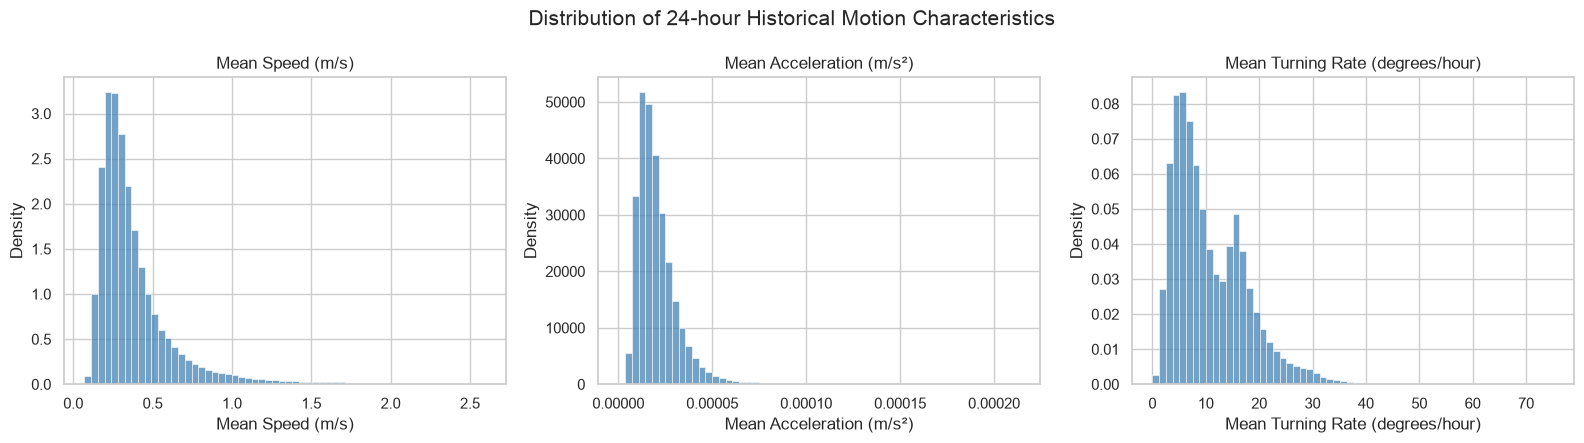

In [6]:
features = [
    ("mean_speed_24h", "Mean Speed (m/s)"),
    ("mean_acceleration_24h", "Mean Acceleration (m/s²)"),
    ("mean_turning_24h", "Mean Turning Rate (degrees/hour)")
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, (column, label) in zip(axes, features):

    values = motion_df[column].dropna()

    sns.histplot(
        values,
        bins=60,
        stat="density",
        color="steelblue",
        ax=ax
    )

    ax.set_title(label)
    ax.set_xlabel(label)
    ax.set_ylabel("Density")

plt.suptitle(
    "Distribution of 24-hour Historical Motion Characteristics",
    fontsize=15
)

plt.tight_layout()
plt.show()

### Motion Characteristics: Feature Engineering

We calculate three motion characteristics from the NOAA drifter velocity observations: **speed, acceleration magnitude, and turning rate**. These features describe how fast a drifter moves and how its motion changes over time.

#### 1. Velocity and Speed

The dataset provides two velocity components:

- `ve`: Eastward velocity (m/s). Positive values indicate eastward movement; negative values indicate westward movement.
- `vn`: Northward velocity (m/s). Positive values indicate northward movement; negative values indicate southward movement.

Together, they form the two-dimensional velocity vector:

\[
\mathbf{v}_t=(ve_t,vn_t)
\]

The **speed** is the magnitude of this vector:

\[
s_t=\sqrt{ve_t^2+vn_t^2}
\]

Speed measures how fast the drifter moves, regardless of direction.

#### 2. Acceleration Magnitude

Acceleration describes how quickly the velocity vector changes between consecutive observations.

For hourly observations, the acceleration magnitude is approximated by:

\[
a_t=\frac{\|\mathbf{v}_t-\mathbf{v}_{t-1}\|}{3600}
\]

where 3600 is the number of seconds in one hour.

- Unit: m/s².
- Larger values indicate more rapid changes in velocity.
- Acceleration captures both changes in speed and changes in direction.

#### 3. Heading and Turning Rate

**Heading** describes the direction of movement:

\[
\theta_t=\operatorname{atan2}(vn_t,ve_t)
\]

The angle is measured counterclockwise from east.

**Turning rate** measures how much this direction changes between consecutive observations:

\[
r_t=\frac{|\operatorname{wrap}(\theta_t-\theta_{t-1})|}{\Delta t}
\]

where `wrap` adjusts angular differences to the interval \([-\pi,\pi]\), avoiding artificial jumps when angles cross the ±180° boundary.

In our hourly data, we express turning rate in degrees/hour.

- A low turning rate indicates relatively straight movement.
- A high turning rate indicates rapid changes in direction.
- Heading becomes unstable at very low speeds, so these observations require special treatment.

#### 4. Historical Motion Features (24-hour Window)

For each forecast origin at time \(t\), we summarise the preceding 24 hours of motion using observations from \(t-24\) to \(t\).

The primary features are:

| Feature | Calculation | Interpretation |
|---|---|---|
| Mean speed | Average of 25 speed observations | Typical movement speed |
| Mean acceleration | Average of 24 hourly acceleration magnitudes | Typical velocity variation |
| Mean turning rate | Average of 24 hourly absolute turning rates | Typical directional variation |

Only consecutive hourly observations are used to calculate acceleration and turning. Incomplete historical windows are excluded from this preliminary analysis.

#### 5. Purpose of the Analysis

These features will help investigate whether drifters with different motion characteristics exhibit different 24-hour position forecast errors.

We will first examine their distributions, then classify motion conditions into **Low, Medium, and High** groups and compare forecast errors across these groups.

All historical features are calculated using observations at or before the forecast origin, avoiding the use of future motion information.

In [7]:
# Current-state constant-velocity prediction
horizon = 24 * 3600
R = 6371.0  # Earth radius (km)

# Approximate displacement in latitude and longitude
motion_df["pred_lat"] = (
    motion_df["lat"]
    + np.degrees(motion_df["vn"] * horizon / (R * 1000))
)

motion_df["pred_lon"] = (
    motion_df["lon"]
    + np.degrees(
        motion_df["ve"] * horizon /
        (R * 1000 * np.cos(np.radians(motion_df["lat"])))
    )
)

# Match actual position exactly 24 hours later
future = df[["trajectory_id", "time", "lat", "lon"]].copy()

future["time"] = future["time"] - pd.Timedelta(hours=24)

future = future.rename(columns={
    "lat": "actual_lat",
    "lon": "actual_lon"
})

motion_df = motion_df.merge(
    future,
    on=["trajectory_id", "time"],
    how="inner"
)

# Great-circle distance error (Haversine)
lat1 = np.radians(motion_df["pred_lat"])
lon1 = np.radians(motion_df["pred_lon"])
lat2 = np.radians(motion_df["actual_lat"])
lon2 = np.radians(motion_df["actual_lon"])

a = (
    np.sin((lat2 - lat1) / 2)**2
    + np.cos(lat1) * np.cos(lat2)
    * np.sin((lon2 - lon1) / 2)**2
)

motion_df["error_km"] = (
    2 * R * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
)

In [8]:
features = {
    "Speed": "mean_speed_24h",
    "Acceleration": "mean_acceleration_24h",
    "Turning": "mean_turning_24h"
}

for name, column in features.items():

    motion_df[f"{name}_group"] = pd.qcut(
        motion_df[column],
        q=3,
        labels=["Low", "Mid", "High"]
    )

In [9]:
results = {}

for name in features:

    summary = (
        motion_df
        .groupby(f"{name}_group", observed=True)["error_km"]
        .agg(
            median="median",
            p90=lambda x: x.quantile(0.9),
            count="count"
        )
        .reindex(["Low", "Mid", "High"])
    )

    results[name] = summary

    print(f"\n{name}")
    display(summary)


Speed


,median,p90,count
Speed_group,,,
Low,10.865969,21.152465,445821
Mid,14.309136,28.556508,445820
High,21.964753,52.729527,445821



Acceleration


,median,p90,count
Acceleration_group,,,
Low,10.096737,20.904529,445821
Mid,14.820975,29.775802,445820
High,21.840427,49.591519,445821



Turning


,median,p90,count
Turning_group,,,
Low,14.033702,40.877794,445821
Mid,12.567362,29.388139,445820
High,17.058678,35.544345,445821


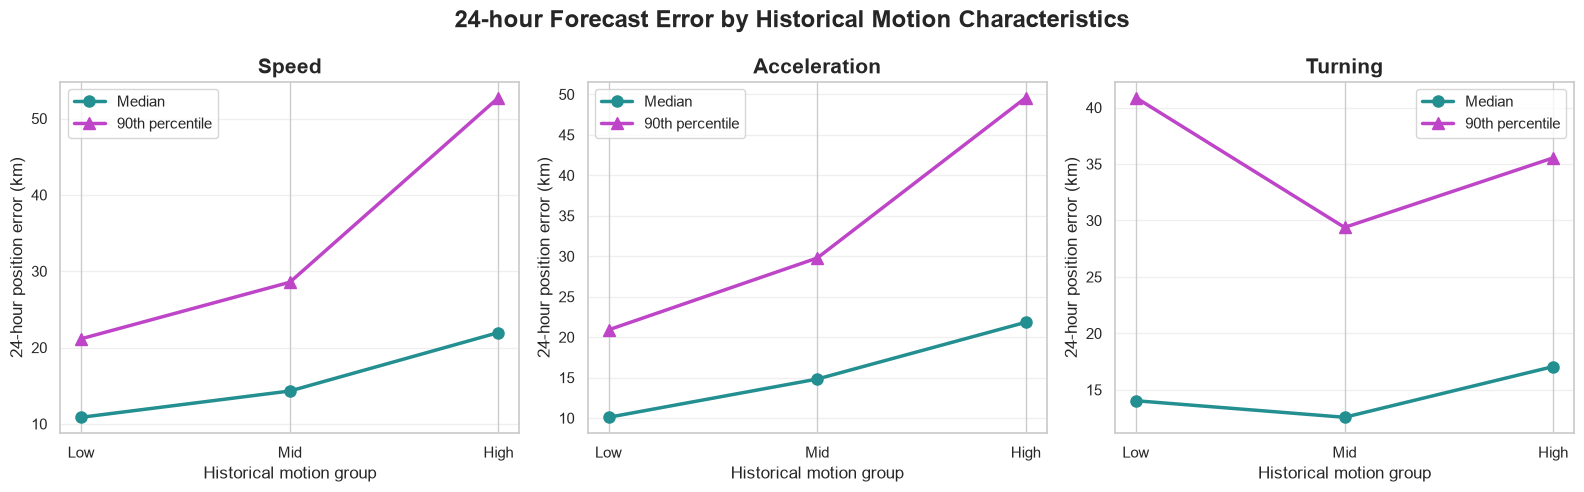

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

colors = {
    "median": "#238F91",
    "p90": "#BE45C8"
}

for ax, (name, summary) in zip(axes, results.items()):

    x = np.arange(3)

    ax.plot(
        x, summary["median"],
        marker="o",
        linewidth=2.5,
        markersize=8,
        color=colors["median"],
        label="Median"
    )

    ax.plot(
        x, summary["p90"],
        marker="^",
        linewidth=2.5,
        markersize=8,
        color=colors["p90"],
        label="90th percentile"
    )

    ax.set_xticks(x)
    ax.set_xticklabels(["Low", "Mid", "High"])

    ax.set_title(name, fontsize=15, fontweight="bold")
    ax.set_ylabel("24-hour position error (km)")
    ax.set_xlabel("Historical motion group")

    ax.legend()
    ax.grid(axis="y", alpha=0.3)

plt.suptitle(
    "24-hour Forecast Error by Historical Motion Characteristics",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "../image/error_by_motion_characteristics.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Forecasting Framework

### 1. Prediction Task

We aim to predict the future position of Gulf Stream drifters **24 hours ahead**, using their current state and motion history over the preceding 24 hours.

For each forecast origin at time \(t\):

- **Input:** 25 consecutive hourly observations from \(t-24\) to \(t\).
- **Target:** Observed drifter position at exactly \(t+24\) hours.
- **Output:** Predicted future longitude and latitude.
- **Evaluation:** Great-circle distance between predicted and observed positions (km).

### 2. Historical Motion Features

Three characteristics describe recent drifter movement:

| Feature | Definition | Historical summary |
|---|---|---|
| Speed | \(s_t=\sqrt{ve_t^2+vn_t^2}\) | Mean of 25 hourly speeds |
| Acceleration | \(a_t=\|\mathbf v_t-\mathbf v_{t-1}\|/3600\) | Mean of 24 hourly magnitudes |
| Turning | Absolute wrapped change in heading | Mean of 24 hourly turning rates |

Here, \(ve\) and \(vn\) represent eastward and northward velocity components (m/s).

Only consecutive hourly observations are used. Turning is treated as undefined when the speed is below the preliminary threshold of 0.05 m/s.

### 3. Prediction Methods

**Physical baselines**

- **Persistence:** Assumes the drifter remains at its current position.
- **Constant Velocity:** Extrapolates the current eastward and northward velocity over 24 hours.
- **Regional Mean-flow Advection:** Uses an estimated regional mean velocity field to predict future displacement (planned or under development).

For constant velocity, in local Cartesian coordinates measured in metres:

\[
\widehat{\mathbf p}_{t+24}
=\mathbf p_t+86400\mathbf v_t
\]

**Statistical models (planned)**

We will compare two feature configurations:

- **Current-state model:** Uses current position, velocity and selected contextual features.
- **History-enhanced model:** Uses the same current-state features plus historical motion summaries.

Both configurations will be evaluated using regularised linear regression and gradient-boosted regression.

### 4. Model Evaluation

Forecast performance will be measured using:

- **Median position error (km):** Typical prediction accuracy.
- **90th-percentile error (km):** Performance on more difficult forecasts.
- **Relative error reduction (%):** Improvement over the corresponding current-state model.

\[
\text{Error Reduction}=
\frac{E_{\text{current}}-E_{\text{history}}}
{E_{\text{current}}}\times100\%
\]

Models will be compared on identical held-out forecast origins, with data partitioned by drifter ID to reduce leakage between training and evaluation.

### 5. Current Progress

Preliminary analysis has established:

- The distribution of historical speed, acceleration and turning characteristics.
- Initial 24-hour position-error distributions for simple physical baselines.
- An exploratory relationship between motion characteristics and constant-velocity forecast error.

The current pilot uses a fixed random 70% sample of drifter IDs (seed 42) and available July–September extract records. These preliminary results are not yet a held-out evaluation.

The next stage is to construct the formal modelling dataset and evaluate whether historical motion information improves forecast accuracy.

In [11]:
# Median forecast error by Speed × Turning
interaction_median = motion_df.pivot_table(
    index="Speed_group",
    columns="Turning_group",
    values="error_km",
    aggfunc="median",
    observed=True
).reindex(
    index=["Low", "Mid", "High"],
    columns=["Low", "Mid", "High"]
)

# 90th percentile error
interaction_p90 = motion_df.pivot_table(
    index="Speed_group",
    columns="Turning_group",
    values="error_km",
    aggfunc=lambda x: x.quantile(0.9),
    observed=True
).reindex(
    index=["Low", "Mid", "High"],
    columns=["Low", "Mid", "High"]
)

# Number of forecast origins
interaction_count = motion_df.pivot_table(
    index="Speed_group",
    columns="Turning_group",
    values="error_km",
    aggfunc="count",
    observed=True
).reindex(
    index=["Low", "Mid", "High"],
    columns=["Low", "Mid", "High"]
)

display(interaction_median.round(2))
display(interaction_p90.round(2))
display(interaction_count)

Turning_group,Low,Mid,High
Speed_group,,,
Low,7.48,9.23,13.15
Mid,10.13,13.30,20.47
High,19.31,21.31,35.29


Turning_group,Low,Mid,High
Speed_group,,,
Low,14.86,18.13,23.16
Mid,20.37,25.72,33.16
High,50.49,48.07,62.79


Turning_group,Low,Mid,High
Speed_group,,,
Low,46812,167320,231689
Mid,124026,172451,149343
High,274983,106049,64789


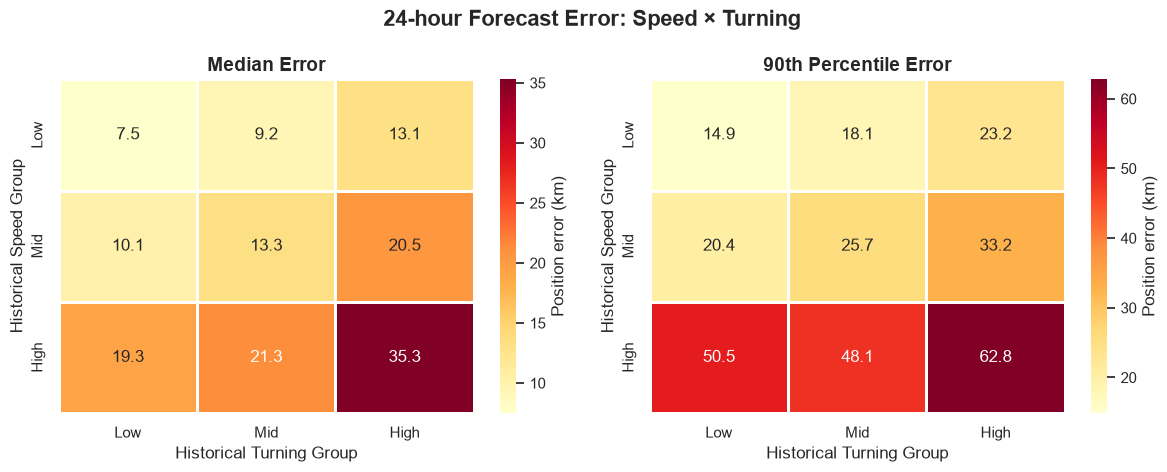

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

for ax, data, title in zip(
    axes,
    [interaction_median, interaction_p90],
    ["Median Error", "90th Percentile Error"]
):
    sns.heatmap(
        data,
        annot=True,
        fmt=".1f",
        cmap="YlOrRd",
        linewidths=0.8,
        linecolor="white",
        cbar_kws={"label": "Position error (km)"},
        ax=ax
    )

    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.set_xlabel("Historical Turning Group")
    ax.set_ylabel("Historical Speed Group")

plt.suptitle(
    "24-hour Forecast Error: Speed × Turning",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "../image/speed_turning_interaction.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Statistical Inference: Motion Characteristics and Forecast Error

### Multivariable Regression with Interaction

We investigate the association between historical motion characteristics and 24-hour constant-velocity forecast error using a multivariable linear regression model.

The response variable is the log-transformed great-circle position error:

\[
Y_i=\log(1+E_i)
\]

where \(E_i\) is measured in kilometres.

The model includes historical mean speed, acceleration, turning rate, and a speed–turning interaction:

\[
Y_i=\beta_0+\beta_1S_i+\beta_2A_i+\beta_3T_i+\beta_4S_iT_i+\varepsilon_i
\]

Predictors are standardised before fitting the model.

To account for dependence between observations from the same drifter, we use cluster-robust standard errors grouped by trajectory ID.

We report coefficient estimates, 95% confidence intervals, and hypothesis tests, with particular attention to the speed–turning interaction.

This analysis estimates statistical associations rather than causal effects.

In [13]:
import statsmodels.formula.api as smf

inference_df = motion_df[[
    "trajectory_id",
    "error_km",
    "mean_speed_24h",
    "mean_acceleration_24h",
    "mean_turning_24h"
]].dropna().copy()

# Standardise predictors
features = {
    "mean_speed_24h": "speed_z",
    "mean_acceleration_24h": "acceleration_z",
    "mean_turning_24h": "turning_z"
}

for original, new in features.items():
    x = inference_df[original]
    inference_df[new] = (x - x.mean()) / x.std()

# Log-transform forecast error
inference_df["log_error"] = np.log1p(
    inference_df["error_km"]
)

# Multivariable regression with interaction
model = smf.ols(
    formula=(
        "log_error ~ speed_z + acceleration_z "
        "+ turning_z + speed_z:turning_z"
    ),
    data=inference_df
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": inference_df["trajectory_id"]
    }
)

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:              log_error   R-squared:                       0.312
Model:                            OLS   Adj. R-squared:                  0.312
Method:                 Least Squares   F-statistic:                     882.1
Date:                Mon, 12 Oct 2026   Prob (F-statistic):               0.00
Time:                        12:01:54   Log-Likelihood:            -1.1826e+06
No. Observations:             1337462   AIC:                         2.365e+06
Df Residuals:                 1337457   BIC:                         2.365e+06
Df Model:                           4                                         
Covariance Type:              cluster                                         
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept             2.8177      0.00

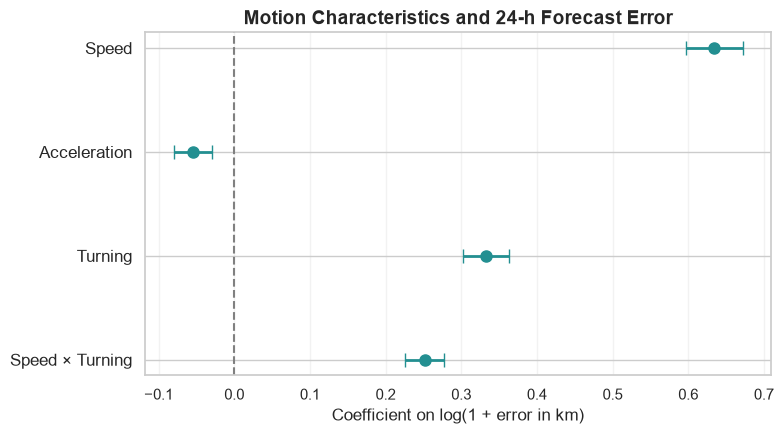

In [14]:
# Extract regression coefficients and 95% confidence intervals
terms = [
    "speed_z",
    "acceleration_z",
    "turning_z",
    "speed_z:turning_z"
]

labels = [
    "Speed",
    "Acceleration",
    "Turning",
    "Speed × Turning"
]

coef = model.params.loc[terms]
ci = model.conf_int().loc[terms]

fig, ax = plt.subplots(figsize=(8, 4.5))

y = np.arange(len(terms))

ax.errorbar(
    coef.values,
    y,
    xerr=[
        coef.values - ci[0].values,
        ci[1].values - coef.values
    ],
    fmt="o",
    markersize=8,
    capsize=5,
    linewidth=2,
    color="#238F91",
    ecolor="#238F91"
)

ax.axvline(
    0, color="gray",
    linestyle="--", linewidth=1.5
)

ax.set_yticks(y)
ax.set_yticklabels(labels, fontsize=12)
ax.invert_yaxis()

ax.set_xlabel(
    "Coefficient on log(1 + error in km)",
    fontsize=12
)

ax.set_title(
    "Motion Characteristics and 24-h Forecast Error",
    fontsize=14,
    fontweight="bold"
)

ax.grid(axis="x", alpha=0.25)

plt.tight_layout()

plt.savefig(
    "../image/regression_coefficients.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Low Speed (-1 SD): n=160,063, turning range=[-0.79, 3.10]
Average Speed: n=309,403, turning range=[-1.16, 1.95]
High Speed (+1 SD): n=69,898, turning range=[-1.30, 1.45]


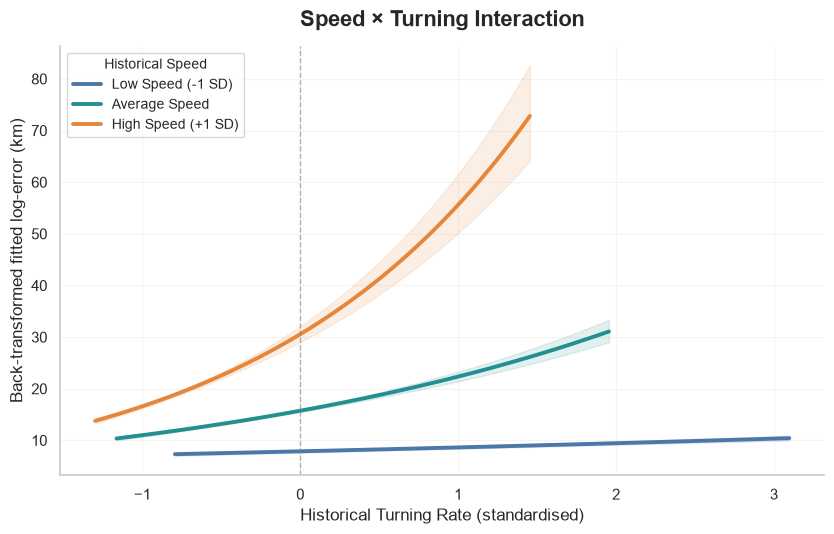

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Speed levels in standardised units
speed_levels = {
    "Low Speed (-1 SD)": -1,
    "Average Speed": 0,
    "High Speed (+1 SD)": 1
}

colors = ["#4C78A8", "#238F91", "#E6863B"]

fig, ax = plt.subplots(figsize=(8.5, 5.5))

# Restrict turning range to observed data near each speed level
# Use +/- 0.25 SD around each selected speed
speed_bandwidth = 0.25

for (label, speed), color in zip(
    speed_levels.items(), colors
):

    subset = inference_df.loc[
        (inference_df["speed_z"] >= speed - speed_bandwidth)
        & (inference_df["speed_z"] <= speed + speed_bandwidth),
        "turning_z"
    ].dropna()

    if len(subset) < 100:
        print(f"Insufficient observations for {label}")
        continue

    # Use the central 95% of observed turning values
    turning_min, turning_max = subset.quantile([0.025, 0.975])

    turning_range = np.linspace(
        turning_min,
        turning_max,
        100
    )

    prediction_df = pd.DataFrame({
        "speed_z": speed,
        "acceleration_z": 0,
        "turning_z": turning_range
    })

    prediction = model.get_prediction(
        prediction_df
    ).summary_frame(alpha=0.05)

    # Back-transform fitted log-error to km scale
    predicted_error = np.expm1(
        prediction["mean"].to_numpy()
    )

    lower = np.expm1(
        prediction["mean_ci_lower"].to_numpy()
    )

    upper = np.expm1(
        prediction["mean_ci_upper"].to_numpy()
    )

    # Fitted relationship
    ax.plot(
        turning_range,
        predicted_error,
        label=label,
        color=color,
        linewidth=2.8
    )

    # 95% confidence interval
    ax.fill_between(
        turning_range,
        lower,
        upper,
        color=color,
        alpha=0.13
    )

    print(
        f"{label}: n={len(subset):,}, "
        f"turning range=[{turning_min:.2f}, {turning_max:.2f}]"
    )

# Reference line at mean turning
ax.axvline(
    0,
    color="gray",
    linestyle="--",
    linewidth=1,
    alpha=0.6
)

ax.set_xlabel(
    "Historical Turning Rate (standardised)",
    fontsize=12
)

ax.set_ylabel(
    "Back-transformed fitted log-error (km)",
    fontsize=12
)

ax.set_title(
    "Speed × Turning Interaction",
    fontsize=16,
    fontweight="bold",
    pad=14
)

ax.legend(
    title="Historical Speed",
    fontsize=10,
    title_fontsize=10,
    loc="upper left",
    frameon=True
)

ax.grid(
    alpha=0.2,
    linewidth=0.8
)

ax.tick_params(labelsize=11)

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    "../image/speed_turning_regression.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Statistical Inference — Summary

### Multivariable Regression Results

We fitted an OLS regression model to investigate how historical motion characteristics are associated with 24-hour constant-velocity forecast error.

The response variable was log-transformed position error, $\log(1+E)$, and the predictors included standardised historical speed, acceleration, turning rate, and a speed–turning interaction.

Cluster-robust standard errors were used to account for within-drifter dependence.

**Model summary:**
- **Observations:** 1,337,462 forecast origins
- **R²:** 0.312
- **Speed:** β = 0.634, 95% CI [0.597, 0.672]
- **Acceleration:** β = −0.055, 95% CI [−0.080, −0.029]
- **Turning:** β = 0.333, 95% CI [0.303, 0.363]
- **Speed × Turning:** β = 0.251, 95% CI [0.225, 0.277], p < 0.001

### Key Findings

**1. Historical speed is strongly associated with forecast error.**

Higher historical speed is associated with larger 24-hour position errors, conditional on the other predictors and their interaction.

**2. Speed and turning exhibit a positive interaction.**

The association between turning and forecast error becomes stronger as historical speed increases.

The interaction plot illustrates this relationship at three standardised speed levels:

- Low Speed (−1 SD): 160,063 nearby observations
- Average Speed: 309,403 nearby observations
- High Speed (+1 SD): 69,898 nearby observations

The turning ranges were restricted to the central 95% of observed values within each speed band to reduce extrapolation.

**3. Acceleration shows a negative adjusted coefficient.**

Although the preliminary EDA suggested a positive association between acceleration and forecast error, the multivariable regression produced a small negative coefficient. This reversal may reflect correlations among motion characteristics or model specification.

### Interpretation and Limitations

These findings indicate that forecast difficulty is associated with both individual motion characteristics and their interactions.

However, the analysis is observational and exploratory. The regression explains variation in existing baseline errors rather than demonstrating improvements in future position prediction. Confidence intervals account for within-drifter clustering but do not eliminate potential confounding or model misspecification.

---

## Making Predictions — Model Development and Evaluation

The next stage investigates whether incorporating historical motion information improves 24-hour drifter position forecasts.

We will compare:

1. **Physical baselines:** Persistence and constant-velocity extrapolation.
2. **Current-state regression:** Prediction using current position and velocity.
3. **History-enhanced regression:** The same model with additional 24-hour historical motion features.
4. **Gradient boosting:** Nonlinear prediction models with and without historical features.

Models will be evaluated on held-out drifter trajectories using:

- Median great-circle position error (km)
- 90th-percentile position error (km)
- Relative error reduction against the corresponding baseline

The central objective is to determine whether historical motion information provides measurable predictive improvement beyond the current state alone.

In [16]:
import numpy as np
import pandas as pd

# Earth radius in metres
R = 6371000.0

# Convert actual future position into displacement (metres)
lat0 = np.radians(motion_df["lat"].to_numpy())
lon0 = np.radians(motion_df["lon"].to_numpy())

lat1 = np.radians(motion_df["actual_lat"].to_numpy())
lon1 = np.radians(motion_df["actual_lon"].to_numpy())

# Eastward and northward displacement
actual_dx = R * np.cos(lat0) * (lon1 - lon0)
actual_dy = R * (lat1 - lat0)

# Constant-velocity predicted displacement
horizon = 24 * 3600

baseline_dx = motion_df["ve"].to_numpy() * horizon
baseline_dy = motion_df["vn"].to_numpy() * horizon

# Target: correction to constant-velocity prediction
motion_df["target_dx"] = actual_dx - baseline_dx
motion_df["target_dy"] = actual_dy - baseline_dy

In [17]:
# Current-state features
current_features = [
    "lon",
    "lat",
    "ve",
    "vn"
]

# Historical motion features
history_features = [
    "mean_speed_24h",
    "mean_acceleration_24h",
    "mean_turning_24h"
]

# Full feature set
enhanced_features = (
    current_features + history_features
)

# Prediction targets
target_columns = [
    "target_dx",
    "target_dy"
]

In [18]:
# Columns required for modelling
required_columns = (
    ["trajectory_id", "time", "study_period"]
    + enhanced_features
    + target_columns
)

modelling_df = (
    motion_df[required_columns]
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
    .copy()
)

# Sort observations
modelling_df = modelling_df.sort_values(
    ["trajectory_id", "time"]
).reset_index(drop=True)

print("Modelling dataset created.")
print(f"Forecast origins: {len(modelling_df):,}")
print(
    "Distinct drifters:",
    modelling_df["trajectory_id"].nunique()
)

print("\nStudy periods:")
print(
    modelling_df["study_period"].value_counts()
)

print("\nCurrent-only features:")
print(current_features)

print("\nHistory-enhanced features:")
print(enhanced_features)

print("\nTarget columns:")
print(target_columns)

Modelling dataset created.
Forecast origins: 1,337,462
Distinct drifters: 944

Study periods:
study_period
2011-2014    353875
2007-2010    341718
2019-2022    330886
2015-2018    310983
Name: count, dtype: int64

Current-only features:
['lon', 'lat', 've', 'vn']

History-enhanced features:
['lon', 'lat', 've', 'vn', 'mean_speed_24h', 'mean_acceleration_24h', 'mean_turning_24h']

Target columns:
['target_dx', 'target_dy']


In [19]:
output_path = "../data/processed/modelling_dataset.parquet"

modelling_df.to_parquet(
    output_path,
    index=False
)

print(f"Saved to: {output_path}")
print(
    f"Shape: {modelling_df.shape}"
)

Saved to: ../data/processed/modelling_dataset.parquet
Shape: (1337462, 12)


In [20]:
from sklearn.model_selection import train_test_split
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Unique drifter IDs
drifter_ids = modelling_df["trajectory_id"].unique()

# 70% train, 30% remaining
train_ids, remaining_ids = train_test_split(
    drifter_ids,
    test_size=0.30,
    random_state=42
)

# Divide remaining IDs equally into validation and test
val_ids, test_ids = train_test_split(
    remaining_ids,
    test_size=0.50,
    random_state=42
)

# Assign split labels
modelling_df["split"] = "test"

modelling_df.loc[
    modelling_df["trajectory_id"].isin(train_ids),
    "split"
] = "train"

modelling_df.loc[
    modelling_df["trajectory_id"].isin(val_ids),
    "split"
] = "validation"

# Create separate datasets
train_df = modelling_df[
    modelling_df["split"] == "train"
].copy()

val_df = modelling_df[
    modelling_df["split"] == "validation"
].copy()

test_df = modelling_df[
    modelling_df["split"] == "test"
].copy()

print("Dataset split completed.")

Dataset split completed.


In [21]:
split_summary = (
    modelling_df
    .groupby("split")
    .agg(
        forecast_origins=("trajectory_id", "size"),
        distinct_drifters=("trajectory_id", "nunique")
    )
    .reindex(["train", "validation", "test"])
)

split_summary["origin_percentage"] = (
    100 * split_summary["forecast_origins"]
    / len(modelling_df)
)

split_summary["drifter_percentage"] = (
    100 * split_summary["distinct_drifters"]
    / modelling_df["trajectory_id"].nunique()
)

display(split_summary.round(2))

# Study-period distribution
period_summary = pd.crosstab(
    modelling_df["study_period"],
    modelling_df["split"]
)

period_summary = period_summary[
    ["train", "validation", "test"]
]

display(period_summary)

,forecast_origins,distinct_drifters,origin_percentage,drifter_percentage
split,,,,
train,920851,660,68.85,69.92
validation,213087,142,15.93,15.04
test,203524,142,15.22,15.04


split,train,validation,test
study_period,,,
2007-2010,226510,74700,40508
2011-2014,254086,37107,62682
2015-2018,221882,39432,49669
2019-2022,218373,61848,50665


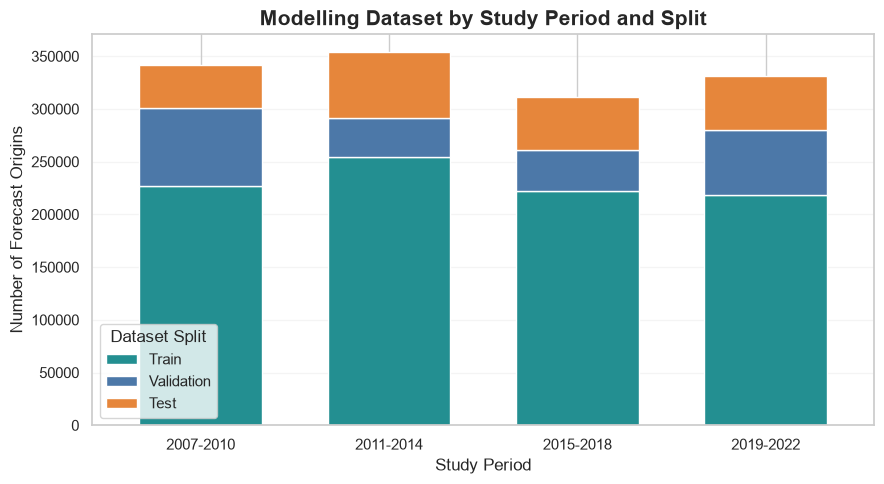

In [22]:
fig, ax = plt.subplots(figsize=(9, 5))

period_summary.plot(
    kind="bar",
    stacked=True,
    ax=ax,
    color=["#238F91", "#4C78A8", "#E6863B"],
    edgecolor="white",
    width=0.65
)

ax.set_title(
    "Modelling Dataset by Study Period and Split",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Study Period", fontsize=12)
ax.set_ylabel("Number of Forecast Origins", fontsize=12)

ax.legend(
    title="Dataset Split",
    labels=["Train", "Validation", "Test"]
)

ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    "../image/modelling_data_split.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [23]:
modelling_df.to_parquet(
    "../data/processed/modelling_dataset_split.parquet",
    index=False
)

print("Saved modelling dataset with split labels.")

Saved modelling dataset with split labels.


In [24]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

# Feature configurations
feature_sets = {
    "Current-only Ridge": current_features,
    "History-enhanced Ridge": enhanced_features
}

# Regularisation strengths
alphas = [0.1, 1.0, 10.0, 100.0, 1000.0]

# Targets
y_train = train_df[target_columns]
y_val = val_df[target_columns]

ridge_models = {}
ridge_predictions = {}

for name, features in feature_sets.items():

    X_train = train_df[features]
    X_val = val_df[features]

    best_score = np.inf
    best_model = None
    best_alpha = None

    for alpha in alphas:

        pipeline = make_pipeline(
            StandardScaler(),
            Ridge(alpha=alpha)
        )

        pipeline.fit(X_train, y_train)

        pred = pipeline.predict(X_val)

        # Validation RMSE in displacement-correction space
        rmse = np.sqrt(
            np.mean(np.sum(
                (pred - y_val.to_numpy())**2,
                axis=1
            ))
        )

        if rmse < best_score:
            best_score = rmse
            best_model = pipeline
            best_alpha = alpha

    ridge_models[name] = best_model
    ridge_predictions[name] = best_model.predict(X_val)

    print(
        f"{name}: "
        f"best alpha={best_alpha}, "
        f"validation displacement RMSE={best_score / 1000:.2f} km"
    )

Current-only Ridge: best alpha=0.1, validation displacement RMSE=19.28 km
History-enhanced Ridge: best alpha=0.1, validation displacement RMSE=19.04 km


In [25]:
R = 6371000.0
horizon = 24 * 3600

def calculate_forecast_error(data, corrections):

    lat = np.radians(data["lat"].to_numpy())
    lon = np.radians(data["lon"].to_numpy())

    ve = data["ve"].to_numpy()
    vn = data["vn"].to_numpy()

    # Baseline displacement + model correction
    dx = ve * horizon + corrections[:, 0]
    dy = vn * horizon + corrections[:, 1]

    # Convert displacement to predicted coordinates
    pred_lat = lat + dy / R

    pred_lon = lon + dx / (
        R * np.cos(lat)
    )

    # Reconstruct actual future position from targets
    actual_dx = (
        data["target_dx"].to_numpy()
        + ve * horizon
    )

    actual_dy = (
        data["target_dy"].to_numpy()
        + vn * horizon
    )

    actual_lat = lat + actual_dy / R

    actual_lon = lon + actual_dx / (
        R * np.cos(lat)
    )

    # Haversine distance
    a = (
        np.sin((actual_lat - pred_lat) / 2)**2
        + np.cos(pred_lat) * np.cos(actual_lat)
        * np.sin((actual_lon - pred_lon) / 2)**2
    )

    error_km = (
        2 * R / 1000
        * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
    )

    return error_km


# Constant-velocity baseline (zero correction)
baseline_corrections = np.zeros(
    (len(val_df), 2)
)

validation_errors = {
    "Constant Velocity": calculate_forecast_error(
        val_df,
        baseline_corrections
    )
}

# Ridge model errors
for name, predictions in ridge_predictions.items():

    validation_errors[name] = calculate_forecast_error(
        val_df,
        predictions
    )

In [26]:
comparison = []

baseline_median = np.median(
    validation_errors["Constant Velocity"]
)

for name, errors in validation_errors.items():

    median_error = np.median(errors)
    p90_error = np.percentile(errors, 90)
    mean_error = np.mean(errors)

    improvement = (
        (baseline_median - median_error)
        / baseline_median * 100
    )

    comparison.append({
        "Model": name,
        "Median Error (km)": median_error,
        "Mean Error (km)": mean_error,
        "P90 Error (km)": p90_error,
        "Median Improvement (%)": improvement
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df.round(2))

,Model,Median Error (km),Mean Error (km),P90 Error (km),Median Improvement (%)
0,Constant Velocity,14.14,17.63,33.66,0.00
1,Current-only Ridge,12.17,15.14,28.84,13.95
2,History-enhanced Ridge,12.12,15.01,28.43,14.27


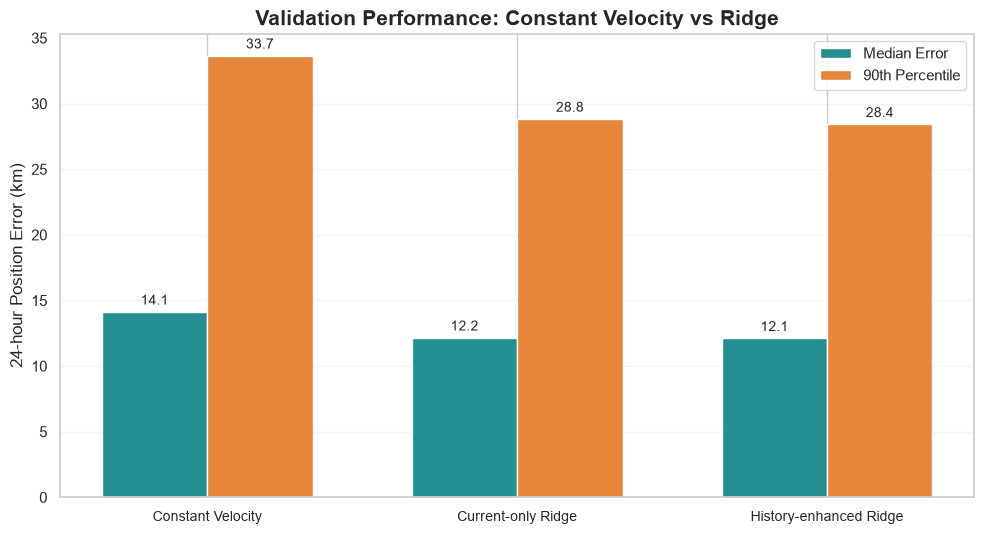

In [27]:
fig, ax = plt.subplots(figsize=(10, 5.5))

x = np.arange(len(comparison_df))
width = 0.34

median_values = comparison_df["Median Error (km)"]
p90_values = comparison_df["P90 Error (km)"]

bars1 = ax.bar(
    x - width / 2,
    median_values,
    width,
    label="Median Error",
    color="#238F91"
)

bars2 = ax.bar(
    x + width / 2,
    p90_values,
    width,
    label="90th Percentile",
    color="#E6863B"
)

ax.bar_label(
    bars1,
    fmt="%.1f",
    padding=3,
    fontsize=10
)

ax.bar_label(
    bars2,
    fmt="%.1f",
    padding=3,
    fontsize=10
)

ax.set_xticks(x)
ax.set_xticklabels(
    comparison_df["Model"],
    fontsize=10
)

ax.set_ylabel(
    "24-hour Position Error (km)",
    fontsize=12
)

ax.set_title(
    "Validation Performance: Constant Velocity vs Ridge",
    fontsize=15,
    fontweight="bold"
)

ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    "../image/ridge_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

R = 6371000.0
H = 24 * 3600

# Create a geographical prediction dataset
geo_df = val_df[
    ["trajectory_id", "time", "lon", "lat",
     "ve", "vn", "target_dx", "target_dy"]
].copy().reset_index(drop=True)

lat_rad = np.radians(geo_df["lat"].to_numpy())
lon_rad = np.radians(geo_df["lon"].to_numpy())

ve = geo_df["ve"].to_numpy()
vn = geo_df["vn"].to_numpy()

# Actual 24-hour displacement
actual_dx = geo_df["target_dx"].to_numpy() + ve * H
actual_dy = geo_df["target_dy"].to_numpy() + vn * H

# Helper: displacement to geographic coordinates
def displacement_to_coords(dx, dy):
    lat_new = lat_rad + dy / R
    lon_new = lon_rad + dx / (R * np.cos(lat_rad))

    return np.degrees(lon_new), np.degrees(lat_new)

# Actual future positions
geo_df["actual_lon"], geo_df["actual_lat"] = (
    displacement_to_coords(actual_dx, actual_dy)
)

# Constant-velocity baseline
geo_df["baseline_lon"], geo_df["baseline_lat"] = (
    displacement_to_coords(ve * H, vn * H)
)

# Ridge predictions
for name, prefix in [
    ("Current-only Ridge", "current"),
    ("History-enhanced Ridge", "enhanced")
]:
    corrections = ridge_predictions[name]

    pred_dx = ve * H + corrections[:, 0]
    pred_dy = vn * H + corrections[:, 1]

    geo_df[f"{prefix}_lon"], geo_df[f"{prefix}_lat"] = (
        displacement_to_coords(pred_dx, pred_dy)
    )

# Attach validation errors
geo_df["baseline_error"] = validation_errors["Constant Velocity"]
geo_df["current_error"] = validation_errors["Current-only Ridge"]
geo_df["enhanced_error"] = validation_errors["History-enhanced Ridge"]

print("Geospatial prediction dataset:", geo_df.shape)

Geospatial prediction dataset: (213087, 19)


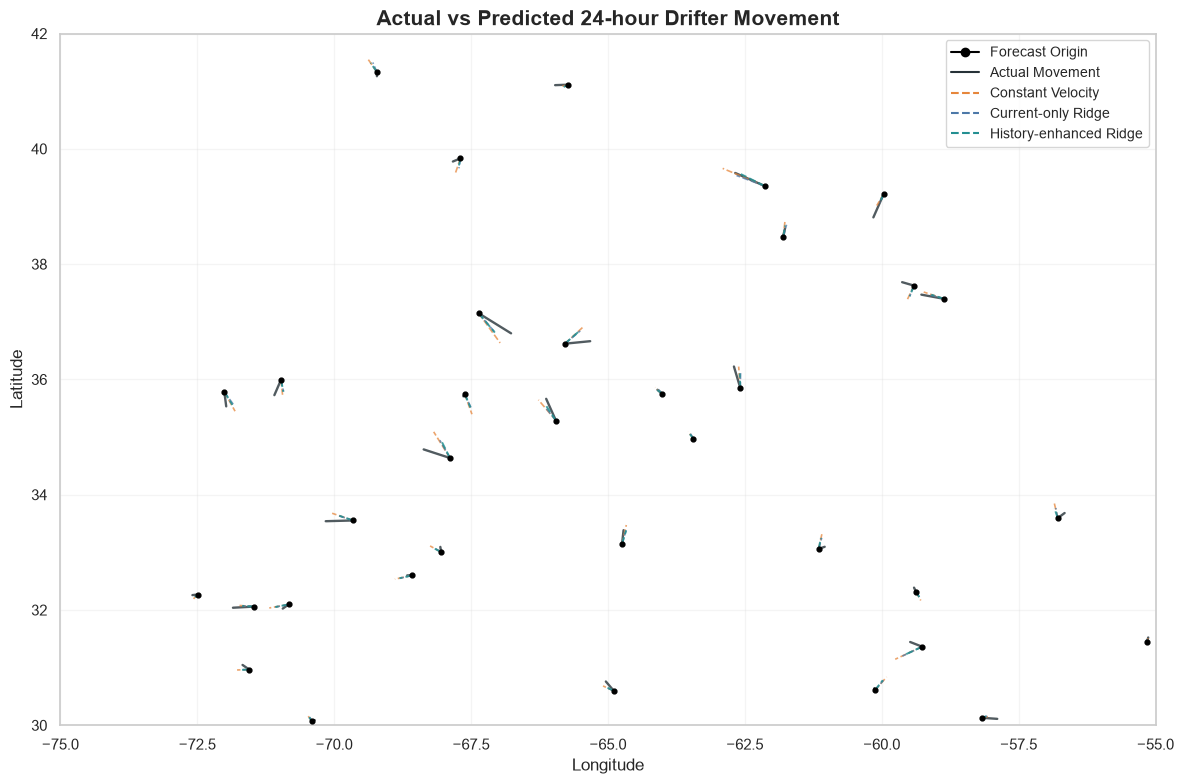

In [29]:
from matplotlib.lines import Line2D

# Focus on a central Gulf Stream window
region = geo_df[
    geo_df["lon"].between(-75, -55)
    & geo_df["lat"].between(30, 42)
].copy()

# Random sample of forecast origins
sample = region.sample(
    n=min(35, len(region)),
    random_state=42
)

fig, ax = plt.subplots(figsize=(12, 8))

for _, row in sample.iterrows():

    x0, y0 = row["lon"], row["lat"]

    # Actual movement
    ax.plot(
        [x0, row["actual_lon"]],
        [y0, row["actual_lat"]],
        color="#263238",
        linewidth=1.7,
        alpha=0.8
    )

    # Constant velocity
    ax.plot(
        [x0, row["baseline_lon"]],
        [y0, row["baseline_lat"]],
        color="#E6863B",
        linestyle="--",
        linewidth=1.2,
        alpha=0.75
    )

    # Current-only Ridge
    ax.plot(
        [x0, row["current_lon"]],
        [y0, row["current_lat"]],
        color="#4C78A8",
        linestyle="--",
        linewidth=1.2,
        alpha=0.75
    )

    # History-enhanced Ridge
    ax.plot(
        [x0, row["enhanced_lon"]],
        [y0, row["enhanced_lat"]],
        color="#238F91",
        linestyle="--",
        linewidth=1.4,
        alpha=0.85
    )

    ax.scatter(
        x0, y0,
        color="black",
        s=12,
        zorder=5
    )

legend_elements = [
    Line2D([0], [0], color="black", marker="o",
           label="Forecast Origin"),
    Line2D([0], [0], color="#263238",
           label="Actual Movement"),
    Line2D([0], [0], color="#E6863B",
           linestyle="--", label="Constant Velocity"),
    Line2D([0], [0], color="#4C78A8",
           linestyle="--", label="Current-only Ridge"),
    Line2D([0], [0], color="#238F91",
           linestyle="--", label="History-enhanced Ridge")
]

ax.legend(
    handles=legend_elements,
    loc="upper right",
    fontsize=10
)

ax.set_xlim(-75, -55)
ax.set_ylim(30, 42)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

ax.set_title(
    "Actual vs Predicted 24-hour Drifter Movement",
    fontsize=15,
    fontweight="bold"
)

ax.grid(alpha=0.2)

plt.tight_layout()

plt.savefig(
    "../image/geo_prediction_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

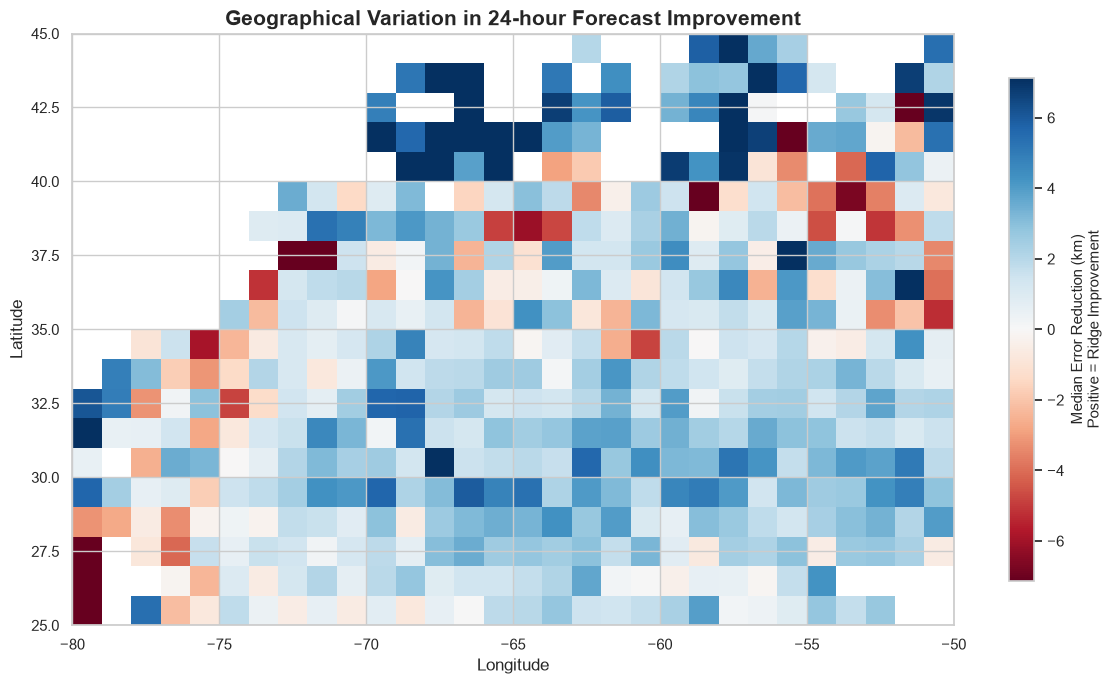

In [30]:
# Restrict to Gulf Stream study region
spatial_df = geo_df[
    geo_df["lon"].between(-80, -50)
    & geo_df["lat"].between(25, 45)
].copy()

# 1-degree spatial grid
spatial_df["lon_bin"] = np.floor(spatial_df["lon"])
spatial_df["lat_bin"] = np.floor(spatial_df["lat"])

# Aggregate errors by spatial cell
spatial_summary = (
    spatial_df
    .groupby(["lat_bin", "lon_bin"])
    .agg(
        n=("baseline_error", "size"),
        baseline_median=("baseline_error", "median"),
        enhanced_median=("enhanced_error", "median")
    )
    .reset_index()
)

spatial_summary["improvement_km"] = (
    spatial_summary["baseline_median"]
    - spatial_summary["enhanced_median"]
)

# Require sufficient observations per cell
spatial_summary = spatial_summary[
    spatial_summary["n"] >= 50
]

# Convert to grid
improvement_grid = spatial_summary.pivot(
    index="lat_bin",
    columns="lon_bin",
    values="improvement_km"
)

# Reindex to full geographical extent
improvement_grid = improvement_grid.reindex(
    index=np.arange(25, 45),
    columns=np.arange(-80, -50)
)

values = improvement_grid.to_numpy()

# Symmetric colour range around zero
limit = np.nanpercentile(np.abs(values), 95)

if not np.isfinite(limit) or limit == 0:
    limit = 1.0

fig, ax = plt.subplots(figsize=(12, 7))

im = ax.imshow(
    values,
    origin="lower",
    extent=[-80, -50, 25, 45],
    cmap="RdBu",
    norm=mcolors.TwoSlopeNorm(
        vmin=-limit,
        vcenter=0,
        vmax=limit
    ),
    aspect="auto",
    interpolation="nearest"
)

cbar = plt.colorbar(im, ax=ax, shrink=0.85)

cbar.set_label(
    "Median Error Reduction (km)\nPositive = Ridge Improvement",
    fontsize=11
)

ax.set_xlabel("Longitude", fontsize=12)
ax.set_ylabel("Latitude", fontsize=12)

ax.set_title(
    "Geographical Variation in 24-hour Forecast Improvement",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "../image/spatial_error_improvement.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Making Predictions — Ridge Regression Results

### Model Performance

We evaluated two Ridge regression models against the constant-velocity baseline using held-out validation drifters.

| Model | Median Error (km) | Mean Error (km) | P90 Error (km) |
|---|---:|---:|---:|
| Constant Velocity | 14.14 | 17.63 | 33.66 |
| Current-only Ridge | 12.17 | 15.14 | 28.84 |
| History-enhanced Ridge | **12.12** | **15.01** | **28.43** |

**Key findings:**

- Current-only Ridge reduced median forecast error by **13.95%** relative to constant-velocity extrapolation.
- History-enhanced Ridge achieved a **14.27%** reduction relative to the same baseline.
- Adding historical motion features provided only a modest additional improvement: 0.05 km in median error and 0.41 km in P90 error compared with Current-only Ridge.

### Geospatial Evaluation

Two geographical visualisations were produced:

1. **Actual vs Predicted 24-hour Movement:** Illustrates the differences between observed displacement, constant-velocity extrapolation and Ridge predictions at selected validation origins.
2. **Spatial Variation in Forecast Improvement:** Maps the difference in grid-level median errors between the constant-velocity baseline and History-enhanced Ridge across the Gulf Stream study region.

The spatial analysis reveals geographical variation in model performance. Some regions show larger error reductions, while others exhibit limited improvement or increased errors.

These results indicate that Ridge regression can improve upon the physical baseline, but the three historical summary features provide limited additional predictive value in a linear modelling framework.

### Limitations

- Results are preliminary and based on the validation set rather than the final held-out test set.
- The models use summary statistics of historical motion rather than the complete velocity time series.
- Spatial error estimates may be unstable in regions with relatively few forecast origins.
- Forecast positions were reconstructed using a local displacement approximation.

---

## Next Stage — Gradient Boosting Regression

We next investigate whether nonlinear models can capture relationships between historical motion characteristics and future displacement that Ridge regression cannot represent.

Two Gradient Boosting models will be trained using the same data partitions:

- **Current-only Gradient Boosting:** Longitude, latitude and current eastward/northward velocity.
- **History-enhanced Gradient Boosting:** Current-state features plus historical mean speed, acceleration and turning rate.

Both models will predict corrections to the constant-velocity forecast.

### Evaluation Objectives

1. Compare nonlinear models against Ridge regression and the physical baseline.
2. Quantify the additional predictive value of historical motion information.
3. Examine spatial differences in forecast performance.
4. Evaluate feature importance to identify influential predictors.

The best-performing model will subsequently be evaluated on the untouched test set.

In [31]:

import numpy as np
import pandas as pd
import time

from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import mean_squared_error

# =====================================================
# 1. Load modelling dataset
# =====================================================

df = pd.read_parquet(
    "../data/processed/modelling_dataset.parquet"
)

print("Original shape:", df.shape)
print("Original drifters:", df["trajectory_id"].nunique())

# =====================================================
# 2. Sample 10% of drifter IDs
# =====================================================

rng = np.random.default_rng(42)

drifter_ids = df["trajectory_id"].unique()

sampled_ids = rng.choice(
    drifter_ids,
    size=max(1, int(len(drifter_ids) * 0.10)),
    replace=False
)

sample_df = df[
    df["trajectory_id"].isin(sampled_ids)
].copy()

print("\nSampled shape:", sample_df.shape)
print("Sampled drifters:", sample_df["trajectory_id"].nunique())

# =====================================================
# 3. Feature sets
# =====================================================

current_features = [
    "lon", "lat", "ve", "vn"
]

history_features = [
    "lon", "lat", "ve", "vn",
    "mean_speed_24h",
    "mean_acceleration_24h",
    "mean_turning_24h"
]

target_cols = ["target_dx", "target_dy"]

# =====================================================
# 4. Trajectory-level train / validation / test split
# =====================================================

split1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_idx, temp_idx = next(
    split1.split(
        sample_df,
        groups=sample_df["trajectory_id"]
    )
)

train_df = sample_df.iloc[train_idx]
temp_df = sample_df.iloc[temp_idx]

split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_idx, test_idx = next(
    split2.split(
        temp_df,
        groups=temp_df["trajectory_id"]
    )
)

val_df = temp_df.iloc[val_idx]
test_df = temp_df.iloc[test_idx]

print("\nDataset splits:")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

# =====================================================
# 5. Model training
# =====================================================

def train_gb(features, label):

    print(f"\nTraining {label}...")
    start = time.time()

    base_model = HistGradientBoostingRegressor(
        max_iter=100,
        max_leaf_nodes=15,
        learning_rate=0.1,
        min_samples_leaf=30,
        early_stopping=True,
        random_state=42
    )

    model = MultiOutputRegressor(base_model)

    model.fit(
        train_df[features],
        train_df[target_cols]
    )

    print(
        f"{label} finished in "
        f"{time.time() - start:.1f} seconds"
    )

    return model


gb_current = train_gb(
    current_features,
    "Current-only GB"
)

gb_history = train_gb(
    history_features,
    "History-enhanced GB"
)

# =====================================================
# 6. Predict validation set
# =====================================================

pred_current = gb_current.predict(
    val_df[current_features]
)

pred_history = gb_history.predict(
    val_df[history_features]
)

actual = val_df[target_cols].to_numpy()

# Euclidean displacement error in km
def displacement_error(pred, actual):
    return np.sqrt(
        np.sum((pred - actual)**2, axis=1)
    )

error_current = displacement_error(
    pred_current, actual
)

error_history = displacement_error(
    pred_history, actual
)

# =====================================================
# 7. Validation results
# =====================================================

results = pd.DataFrame({
    "Model": [
        "Current-only GB",
        "History-enhanced GB"
    ],
    "Median Error (km)": [
        np.median(error_current),
        np.median(error_history)
    ],
    "Mean Error (km)": [
        np.mean(error_current),
        np.mean(error_history)
    ],
    "P90 Error (km)": [
        np.percentile(error_current, 90),
        np.percentile(error_history, 90)
    ]
})

print("\nValidation performance:")
display(results.round(2))

# =====================================================
# 8. Save predictions for later visualisation
# =====================================================

prediction_df = val_df[
    ["trajectory_id", "study_period", "lon", "lat"]
].copy()

prediction_df["actual_dx"] = actual[:, 0]
prediction_df["actual_dy"] = actual[:, 1]

prediction_df["current_pred_dx"] = pred_current[:, 0]
prediction_df["current_pred_dy"] = pred_current[:, 1]

prediction_df["history_pred_dx"] = pred_history[:, 0]
prediction_df["history_pred_dy"] = pred_history[:, 1]

prediction_df["current_error"] = error_current
prediction_df["history_error"] = error_history

prediction_df.to_parquet(
    "../data/processed/gb_validation_predictions.parquet",
    index=False
)

print("\nPredictions saved successfully.")

Original shape: (1337462, 12)
Original drifters: 944

Sampled shape: (138157, 12)
Sampled drifters: 94

Dataset splits:
Train: 95817
Validation: 20195
Test: 22145

Training Current-only GB...
Current-only GB finished in 0.5 seconds

Training History-enhanced GB...
History-enhanced GB finished in 0.5 seconds

Validation performance:


,Model,Median Error (km),Mean Error (km),P90 Error (km)
0,Current-only GB,14190.16,18013.58,36403.33
1,History-enhanced GB,12828.95,17088.80,35967.85



Predictions saved successfully.


In [33]:

from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Confirm target_dx and target_dy are in metres
# before using this conversion.
TO_KM = 1 / 1000

actual = val_df[target_cols].to_numpy()

# 1. Constant velocity baseline
# ve and vn are assumed to be in m/s.
baseline_pred = np.column_stack([
    val_df["ve"].to_numpy() * 24 * 3600,
    val_df["vn"].to_numpy() * 24 * 3600
])

# 2. Ridge models
ridge_current = make_pipeline(
    StandardScaler(),
    Ridge(alpha=10)
)

ridge_history = make_pipeline(
    StandardScaler(),
    Ridge(alpha=10)
)

ridge_current.fit(
    train_df[current_features],
    train_df[target_cols]
)

ridge_history.fit(
    train_df[history_features],
    train_df[target_cols]
)

predictions = {
    "Constant Velocity": baseline_pred,
    "Current-only Ridge": ridge_current.predict(
        val_df[current_features]
    ),
    "History-enhanced Ridge": ridge_history.predict(
        val_df[history_features]
    ),
    "Current-only GB": pred_current,
    "History-enhanced GB": pred_history
}

def position_error_km(pred):
    return np.linalg.norm(
        pred - actual,
        axis=1
    ) * TO_KM

comparison_rows = []

for name, pred in predictions.items():

    errors = position_error_km(pred)

    comparison_rows.append({
        "Model": name,
        "Median Error (km)": np.median(errors),
        "Mean Error (km)": np.mean(errors),
        "P90 Error (km)": np.percentile(errors, 90)
    })

comparison = pd.DataFrame(comparison_rows)

display(comparison.round(2))


,Model,Median Error (km),Mean Error (km),P90 Error (km)
0,Constant Velocity,43.03,52.50,99.56
1,Current-only Ridge,14.65,18.18,35.92
2,History-enhanced Ridge,14.59,18.18,36.10
3,Current-only GB,14.19,18.01,36.40
4,History-enhanced GB,12.83,17.09,35.97


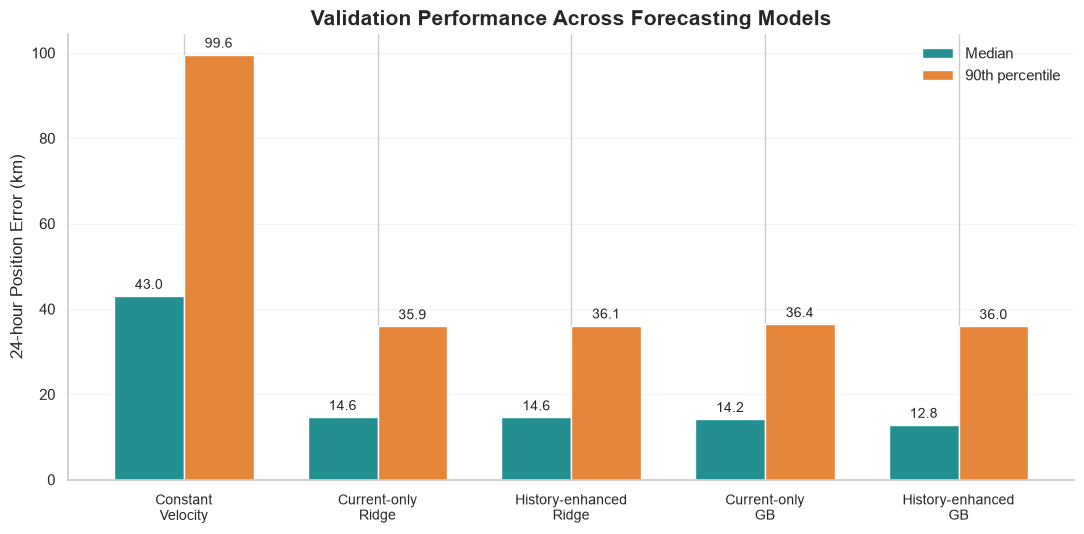

In [34]:

import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(11, 5.5))

x = np.arange(len(comparison))
width = 0.36

colors = ["#238F91", "#E6863B"]

bars1 = ax.bar(
    x - width / 2,
    comparison["Median Error (km)"],
    width,
    label="Median",
    color=colors[0]
)

bars2 = ax.bar(
    x + width / 2,
    comparison["P90 Error (km)"],
    width,
    label="90th percentile",
    color=colors[1]
)

for bars in [bars1, bars2]:
    ax.bar_label(
        bars,
        fmt="%.1f",
        padding=3,
        fontsize=10
    )

ax.set_xticks(x)
ax.set_xticklabels(
    [
        "Constant\nVelocity",
        "Current-only\nRidge",
        "History-enhanced\nRidge",
        "Current-only\nGB",
        "History-enhanced\nGB"
    ],
    fontsize=10
)

ax.set_ylabel(
    "24-hour Position Error (km)",
    fontsize=12
)

ax.set_title(
    "Validation Performance Across Forecasting Models",
    fontsize=15,
    fontweight="bold"
)

ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    "../image/five_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## Prediction: 24-hour Drifter Position Forecasting

### Predictive Models

We developed and compared five forecasting approaches to predict drifter displacement 24 hours ahead:

- **Constant Velocity:** Extrapolates the current eastward and northward velocities.
- **Current-only Ridge:** Linear regression using current position and velocity.
- **History-enhanced Ridge:** Adds mean speed, acceleration and turning rate from the preceding 24 hours.
- **Current-only Gradient Boosting (GB):** Models nonlinear relationships using current-state features.
- **History-enhanced GB:** Combines nonlinear modelling with historical motion characteristics.

### Training and Evaluation

- **Dataset:** 138,157 forecast origins from 94 sampled drifters (10% of available drifter IDs).
- **Splitting:** Trajectory-level training, validation and test separation to avoid sharing drifters across subsets.
- **Validation:** 20,195 forecast origins.
- **Evaluation:** Median, mean and 90th-percentile displacement prediction errors.

### Validation Results

| Model | Median (km) | Mean (km) | P90 (km) |
|---|---:|---:|---:|
| Constant Velocity | 43.03 | 52.50 | 99.56 |
| Current-only Ridge | 14.65 | 18.18 | 35.92 |
| History-enhanced Ridge | 14.59 | 18.18 | 36.10 |
| Current-only GB | 14.19 | 18.01 | 36.40 |
| **History-enhanced GB** | **12.83** | **17.09** | 35.97 |

### Key Findings

1. **History-enhanced GB achieved the lowest median and mean errors**, reducing median error by approximately 12.4% compared with Current-only Ridge.
2. **Historical motion features improved GB performance**, reducing median error from 14.19 km to 12.83 km (9.6%).
3. **Ridge models performed similarly with and without historical features**, suggesting that their additional predictive value may be nonlinear.
4. **Extreme prediction errors remain challenging.** All four statistical models produced 90th-percentile errors of approximately 36 km.

### Interpretation

The results suggest that nonlinear models can better exploit historical drifter motion characteristics for short-term forecasting. However, improvements are more pronounced in typical prediction accuracy than in upper-tail errors.

These findings are preliminary, based on a 10% drifter sample and validation performance rather than final held-out test results.

Valid candidate examples: 26,324
Nearly Straight: drifter=122614, time=2015-09-12 03:00:00+00:00, turning=4.77 deg/h, error=6.19 km
Strong Turning: drifter=300234063942720, time=2018-08-06 00:00:00+00:00, turning=21.34 deg/h, error=32.53 km


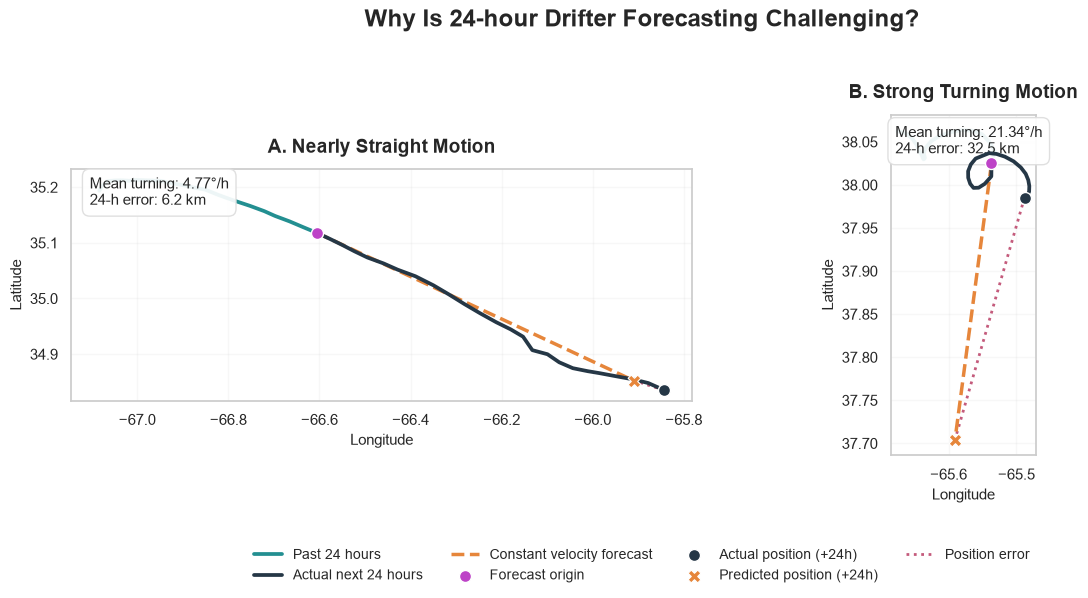

Saved to: ../image/motivation_trajectory_examples.png


In [35]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# 1. Load original drifter trajectories
# ============================================================

DATA_PATH = Path("../data/processed/gulf_stream_trajectories.parquet")
OUTPUT_PATH = Path("../image/motivation_trajectory_examples.png")

OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)

df = pd.read_parquet(
    DATA_PATH,
    columns=["trajectory_id", "time", "lon", "lat", "ve", "vn"]
)

df["time"] = pd.to_datetime(df["time"], utc=True)
df = df.sort_values(["trajectory_id", "time"]).reset_index(drop=True)

# ============================================================
# 2. Geographic helper functions
# ============================================================

R = 6371.0  # Earth radius in km

def haversine(lon1, lat1, lon2, lat2):
    lon1, lat1, lon2, lat2 = map(
        np.radians, [lon1, lat1, lon2, lat2]
    )
    dlon = lon2 - lon1
    dlat = lat2 - lat1

    a = (
        np.sin(dlat / 2)**2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2)**2
    )
    return 2 * R * np.arcsin(np.sqrt(np.clip(a, 0, 1)))


def constant_velocity(lon, lat, ve, vn, hours=24):
    """
    Eastward/northward velocity in m/s.
    Predict longitude and latitude after 24 hours.
    """
    dt = hours * 3600

    dx = ve * dt / 1000
    dy = vn * dt / 1000

    pred_lat = lat + np.degrees(dy / R)

    mean_lat = np.radians((lat + pred_lat) / 2)
    pred_lon = lon + np.degrees(
        dx / (R * np.cos(mean_lat))
    )

    return pred_lon, pred_lat


def historical_turning(ve, vn):
    """Mean absolute hourly heading change in degrees."""
    heading = np.arctan2(vn, ve)
    changes = np.angle(np.exp(1j * np.diff(heading)))
    return np.degrees(np.abs(changes)).mean()


# ============================================================
# 3. Find valid 24-hour history + 24-hour future
# ============================================================

candidates = []

for drifter_id, group in df.groupby("trajectory_id", sort=False):

    group = group.reset_index(drop=True)

    if len(group) < 49:
        continue

    times = group["time"].to_numpy(dtype="datetime64[ns]")
    lon = group["lon"].to_numpy()
    lat = group["lat"].to_numpy()
    ve = group["ve"].to_numpy()
    vn = group["vn"].to_numpy()

    # Check hourly continuity over all 49 timestamps.
    hourly = (
        np.diff(times) == np.timedelta64(1, "h")
    )

    # Valid origin i requires 24 history + 24 future hours.
    valid = np.convolve(
        hourly.astype(int),
        np.ones(48, dtype=int),
        mode="valid"
    ) == 48

    origins = np.where(valid)[0] + 24

    # Restrict forecast origins to the project region.
    origins = origins[
        (lon[origins] >= -80)
        & (lon[origins] <= -60)
        & (lat[origins] >= 30)
        & (lat[origins] <= 45)
    ]

    # July–September, 2007–2022
    origin_dates = pd.DatetimeIndex(times[origins])
    origins = origins[
        (origin_dates.month >= 7)
        & (origin_dates.month <= 9)
        & (origin_dates.year >= 2007)
        & (origin_dates.year <= 2022)
    ]

    # Evaluate every 24 hours to reduce search cost.
    origins = origins[::24]

    for i in origins:

        history_slice = slice(i - 24, i + 1)

        values = np.concatenate([
            lon[i-24:i+25],
            lat[i-24:i+25],
            ve[i-24:i+1],
            vn[i-24:i+1]
        ])

        if not np.isfinite(values).all():
            continue

        pred_lon, pred_lat = constant_velocity(
            lon[i], lat[i], ve[i], vn[i]
        )

        error = haversine(
            pred_lon, pred_lat,
            lon[i+24], lat[i+24]
        )

        turning = historical_turning(
            ve[history_slice],
            vn[history_slice]
        )

        speed = np.hypot(ve[i], vn[i])

        if not np.isfinite([error, turning, speed]).all():
            continue

        candidates.append({
            "drifter_id": drifter_id,
            "origin_time": group.loc[i, "time"],
            "turning": turning,
            "error": error,
            "speed": speed,
            "history_lon": lon[i-24:i+1].copy(),
            "history_lat": lat[i-24:i+1].copy(),
            "future_lon": lon[i:i+25].copy(),
            "future_lat": lat[i:i+25].copy(),
            "pred_lon": pred_lon,
            "pred_lat": pred_lat
        })

print(f"Valid candidate examples: {len(candidates):,}")

if len(candidates) == 0:
    raise ValueError("No valid examples found. Check region and time filters.")

# ============================================================
# 4. Select representative examples
# ============================================================

summary = pd.DataFrame([
    {
        "index": j,
        "turning": c["turning"],
        "error": c["error"],
        "speed": c["speed"]
    }
    for j, c in enumerate(candidates)
])

# Use observed quantiles rather than arbitrary fixed cutoffs.
turn_low = summary["turning"].quantile(0.25)
turn_high = summary["turning"].quantile(0.75)

error_low = summary["error"].quantile(0.25)
error_high = summary["error"].quantile(0.75)

# Exclude almost stationary drifters for clearer examples.
speed_min = 0.05

straight_pool = summary[
    (summary["turning"] <= turn_low)
    & (summary["error"] <= error_low)
    & (summary["speed"] >= speed_min)
]

curved_pool = summary[
    (summary["turning"] >= turn_high)
    & (summary["error"] >= error_high)
    & (summary["speed"] >= speed_min)
]

if straight_pool.empty or curved_pool.empty:
    raise ValueError(
        "Not enough examples in the selected groups. "
        "Try relaxing the quantile thresholds."
    )

# Choose near the median of each eligible pool,
# avoiding the most extreme outliers.
straight_idx = (
    (straight_pool["error"] - straight_pool["error"].median())
    .abs().idxmin()
)

curved_idx = (
    (curved_pool["error"] - curved_pool["error"].median())
    .abs().idxmin()
)

straight = candidates[int(summary.loc[straight_idx, "index"])]
curved = candidates[int(summary.loc[curved_idx, "index"])]

for label, example in [
    ("Nearly Straight", straight),
    ("Strong Turning", curved)
]:
    print(
        f"{label}: "
        f"drifter={example['drifter_id']}, "
        f"time={example['origin_time']}, "
        f"turning={example['turning']:.2f} deg/h, "
        f"error={example['error']:.2f} km"
    )

# ============================================================
# 5. Plot geographic trajectory examples
# ============================================================

colors = {
    "history": "#238F91",
    "actual": "#253746",
    "forecast": "#E6863B",
    "origin": "#BD43C7",
    "error": "#C45B7C"
}

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

examples = [
    ("A. Nearly Straight Motion", straight),
    ("B. Strong Turning Motion", curved)
]

for ax, (title, ex) in zip(axes, examples):

    # Past 24-hour trajectory
    ax.plot(
        ex["history_lon"],
        ex["history_lat"],
        color=colors["history"],
        linewidth=2.7,
        label="Past 24 hours",
        zorder=3
    )

    # Actual future 24-hour trajectory
    ax.plot(
        ex["future_lon"],
        ex["future_lat"],
        color=colors["actual"],
        linewidth=2.7,
        label="Actual next 24 hours",
        zorder=4
    )

    # Constant velocity forecast
    origin_lon = ex["history_lon"][-1]
    origin_lat = ex["history_lat"][-1]

    ax.plot(
        [origin_lon, ex["pred_lon"]],
        [origin_lat, ex["pred_lat"]],
        color=colors["forecast"],
        linestyle="--",
        linewidth=2.5,
        label="Constant velocity forecast",
        zorder=3
    )

    # Forecast origin
    ax.scatter(
        origin_lon, origin_lat,
        s=75, color=colors["origin"],
        edgecolor="white", linewidth=1,
        zorder=6, label="Forecast origin"
    )

    # Actual endpoint
    actual_lon = ex["future_lon"][-1]
    actual_lat = ex["future_lat"][-1]

    ax.scatter(
        actual_lon, actual_lat,
        s=75, color=colors["actual"],
        edgecolor="white", linewidth=1,
        zorder=6, label="Actual position (+24h)"
    )

    # Predicted endpoint
    ax.scatter(
        ex["pred_lon"], ex["pred_lat"],
        s=85, marker="X",
        color=colors["forecast"],
        edgecolor="white", linewidth=0.8,
        zorder=7, label="Predicted position (+24h)"
    )

    # Forecast error connector
    ax.plot(
        [actual_lon, ex["pred_lon"]],
        [actual_lat, ex["pred_lat"]],
        color=colors["error"],
        linestyle=":",
        linewidth=2,
        label="Position error",
        zorder=2
    )

    # Convert lon/lat degrees to approximately equal km scaling.
    mean_lat = np.mean(
        np.concatenate([
            ex["history_lat"],
            ex["future_lat"]
        ])
    )
    ax.set_aspect(1 / np.cos(np.radians(mean_lat)))

    ax.set_title(
        title,
        fontsize=14,
        fontweight="bold",
        pad=12
    )

    ax.text(
        0.03, 0.97,
        f"Mean turning: {ex['turning']:.2f}°/h\n"
        f"24-h error: {ex['error']:.1f} km",
        transform=ax.transAxes,
        va="top",
        fontsize=10.5,
        bbox=dict(
            facecolor="white",
            edgecolor="#DDDDDD",
            alpha=0.92,
            boxstyle="round,pad=0.5"
        )
    )

    ax.set_xlabel("Longitude", fontsize=11)
    ax.set_ylabel("Latitude", fontsize=11)
    ax.grid(alpha=0.15)

# Shared legend
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles, labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.035),
    ncol=4,
    frameon=False,
    fontsize=10
)

fig.suptitle(
    "Why Is 24-hour Drifter Forecasting Challenging?",
    fontsize=17,
    fontweight="bold",
    y=1.03
)

plt.tight_layout(rect=[0, 0.10, 1, 1])

plt.savefig(
    OUTPUT_PATH,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print(f"Saved to: {OUTPUT_PATH}")


## Motivation: Why Is Drifter Forecasting Challenging?

Ocean surface drifters provide direct observations of ocean circulation, but their movements are influenced by complex and changing currents, particularly in the Gulf Stream region.

**The challenge:** Simple constant-velocity forecasts assume that drifters maintain their current direction and speed. However, acceleration, turning and nonlinear motion can make future positions difficult to predict.

**Illustrative examples from observed trajectories:**
- **Nearly straight motion:** Mean turning rate = 4.77°/h; 24-hour forecast error = 6.19 km.
- **Strong turning motion:** Mean turning rate = 21.34°/h; 24-hour forecast error = 32.53 km.

These examples illustrate how substantial changes in direction can coincide with larger forecasting errors.

**Our objective:** To investigate how historical motion characteristics influence 24-hour position prediction accuracy, and whether incorporating these features into statistical and machine learning models improves forecasting performance.

*Figure: Two observed drifter trajectories illustrating the difference between nearly straight and strongly turning motion, with constant-velocity forecasts and their corresponding position errors.*

Loaded observations: 1912262
Available SST: 1855133
Selected drifter: 62889
Trajectory period: 2010-08-14 11:00:00+00:00 to 2010-08-16 11:00:00+00:00
Valid SST observations: 1854793
count    1.854793e+06
mean     2.733616e+01
std      2.613282e+00
min      6.201172e-02
25%      2.680499e+01
50%      2.794501e+01
75%      2.880200e+01
max      3.498102e+01
Name: sst_c, dtype: float64


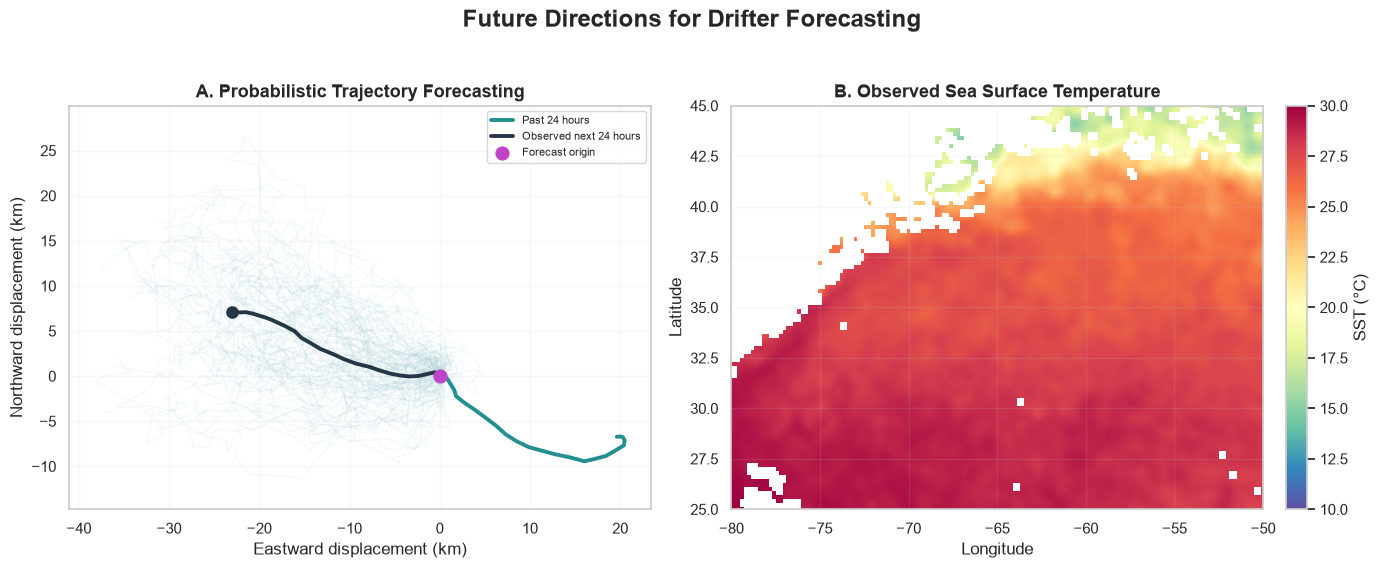

Saved to: ../image/future_work_directions.png


In [40]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.ndimage import gaussian_filter

# =====================================================
# 1. Load processed Gulf Stream data
# =====================================================

data_dir = Path("../data/processed")

files = sorted(
    data_dir.glob("gulf_stream_q3_*.parquet")
)

if not files:
    raise FileNotFoundError(
        "No gulf_stream_q3_*.parquet files found."
    )

required_columns = [
    "trajectory_id",
    "time",
    "lon",
    "lat",
    "sst"
]

frames = []

for file in files:
    part = pd.read_parquet(
        file,
        columns=required_columns
    )
    frames.append(part)

plot_df = pd.concat(
    frames,
    ignore_index=True
)

del frames

plot_df = plot_df.dropna(
    subset=["trajectory_id", "time", "lon", "lat"]
)

plot_df = plot_df[
    plot_df["lon"].between(-80, -50)
    & plot_df["lat"].between(25, 45)
].copy()

plot_df["time"] = pd.to_datetime(
    plot_df["time"],
    utc=True
)

plot_df = plot_df.sort_values(
    ["trajectory_id", "time"]
).reset_index(drop=True)

print("Loaded observations:", len(plot_df))
print("Available SST:", plot_df["sst"].notna().sum())


# =====================================================
# 2. Select a real 49-hour continuous trajectory
# =====================================================

rng = np.random.default_rng(42)

# Hourly continuity within each drifter
time_diff = plot_df.groupby(
    "trajectory_id"
)["time"].diff()

# Each gap must be exactly one hour
continuous = time_diff.eq(
    pd.Timedelta(hours=1)
)

# 48 consecutive hourly gaps = 49 observations
valid_window = (
    continuous.astype(int)
    .groupby(plot_df["trajectory_id"])
    .rolling(48, min_periods=48)
    .sum()
    .reset_index(level=0, drop=True)
    .eq(48)
)

candidate_indices = plot_df.index[
    valid_window.fillna(False)
].to_numpy()

if len(candidate_indices) == 0:
    raise ValueError(
        "No continuous 49-hour trajectory found."
    )

# Randomly choose one valid 49-hour segment
end_idx = rng.choice(candidate_indices)

segment = plot_df.iloc[
    end_idx - 48 : end_idx + 1
].copy()

print(
    "Selected drifter:",
    segment["trajectory_id"].iloc[0]
)

print(
    "Trajectory period:",
    segment["time"].iloc[0],
    "to",
    segment["time"].iloc[-1]
)


# =====================================================
# 3. Convert longitude/latitude to local kilometres
# =====================================================

lat0 = segment["lat"].iloc[24]
lon0 = segment["lon"].iloc[24]

x = (
    (segment["lon"].to_numpy() - lon0)
    * 111.32
    * np.cos(np.radians(lat0))
)

y = (
    (segment["lat"].to_numpy() - lat0)
    * 111.32
)

history_x = x[:25]
history_y = y[:25]

future_x = x[24:]
future_y = y[24:]


# =====================================================
# 4. Illustrative probabilistic trajectories
# =====================================================

# Synthetic uncertainty around the observed future path.
# NOT actual probabilistic model predictions.

n_simulations = 100
n_steps = len(future_x)

simulated_x = np.zeros(
    (n_simulations, n_steps)
)

simulated_y = np.zeros(
    (n_simulations, n_steps)
)

for i in range(n_simulations):

    noise_x = rng.normal(
        0, 1.4, n_steps - 1
    )

    noise_y = rng.normal(
        0, 1.4, n_steps - 1
    )

    perturb_x = np.concatenate([
        [0],
        np.cumsum(noise_x)
    ])

    perturb_y = np.concatenate([
        [0],
        np.cumsum(noise_y)
    ])

    simulated_x[i] = future_x + perturb_x
    simulated_y[i] = future_y + perturb_y


# =====================================================
# 5. Prepare observed SST spatial distribution
# =====================================================


# =====================================================
# 5. Prepare observed SST spatial distribution
# =====================================================

sst_df = plot_df.dropna(subset=["sst"]).copy()

# Convert Kelvin to Celsius
sst_df["sst_c"] = sst_df["sst"] - 273.15

# Remove physically implausible SST observations
sst_df = sst_df[
    sst_df["sst_c"].between(0, 35)
].copy()

print("Valid SST observations:", len(sst_df))
print(sst_df["sst_c"].describe())

# Sample for efficient plotting
if len(sst_df) > 300000:
    sst_df = sst_df.sample(
        n=300000,
        random_state=42
    )

lon_edges = np.linspace(-80, -50, 151)
lat_edges = np.linspace(25, 45, 101)

sst_sum, _, _ = np.histogram2d(
    sst_df["lat"],
    sst_df["lon"],
    bins=[lat_edges, lon_edges],
    weights=sst_df["sst_c"]
)

sst_count, _, _ = np.histogram2d(
    sst_df["lat"],
    sst_df["lon"],
    bins=[lat_edges, lon_edges]
)

# Smooth weighted sums and observation counts
sigma = 1.2

smooth_sum = gaussian_filter(
    sst_sum,
    sigma=sigma
)

smooth_count = gaussian_filter(
    sst_count,
    sigma=sigma
)

sst_grid = np.divide(
    smooth_sum,
    smooth_count,
    out=np.full_like(smooth_sum, np.nan),
    where=smooth_count > 0.1
)

# Keep unobserved cells transparent
sst_grid[sst_count == 0] = np.nan



# =====================================================
# 6. Create poster-ready figure
# =====================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5.5)
)

# -----------------------------------------------------
# LEFT: Probabilistic trajectory illustration
# -----------------------------------------------------

ax = axes[0]

for i in range(n_simulations):

    ax.plot(
        simulated_x[i],
        simulated_y[i],
        color="#7DB9C4",
        alpha=0.08,
        linewidth=1
    )

ax.plot(
    history_x,
    history_y,
    color="#238F91",
    linewidth=2.8,
    label="Past 24 hours"
)

ax.plot(
    future_x,
    future_y,
    color="#253746",
    linewidth=2.8,
    label="Observed next 24 hours"
)

ax.scatter(
    0, 0,
    color="#C044C8",
    s=85,
    zorder=5,
    label="Forecast origin"
)

ax.scatter(
    future_x[-1],
    future_y[-1],
    color="#253746",
    s=65,
    zorder=5
)

ax.set_title(
    "A. Probabilistic Trajectory Forecasting",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel(
    "Eastward displacement (km)"
)

ax.set_ylabel(
    "Northward displacement (km)"
)

ax.set_aspect(
    "equal",
    adjustable="datalim"
)

ax.legend(
    fontsize=8,
    loc="best"
)

ax.grid(alpha=0.15)


# -----------------------------------------------------
# RIGHT: Observed SST spatial distribution
# -----------------------------------------------------

ax = axes[1]

cmap = plt.get_cmap(
    "Spectral_r"
).copy()

cmap.set_bad("white")

im = ax.imshow(
    sst_grid,
    extent=[-80, -50, 25, 45],
    origin="lower",
    cmap=cmap,
    interpolation="bilinear",
    aspect="auto",
    vmin=10,
    vmax=30
)

ax.set_title(
    "B. Observed Sea Surface Temperature",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

cbar = fig.colorbar(
    im,
    ax=ax,
    fraction=0.046,
    pad=0.04
)

cbar.set_label("SST (°C)")

ax.grid(alpha=0.12)


# =====================================================
# 7. Final formatting and export
# =====================================================

fig.suptitle(
    "Future Directions for Drifter Forecasting",
    fontsize=17,
    fontweight="bold",
    y=1.03
)

plt.tight_layout()

output_path = Path(
    "../image/future_work_directions.png"
)

output_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Saved to:", output_path)



## Future Work

### 1. Advanced Spatiotemporal Forecasting

- Current Ridge and Gradient Boosting models use instantaneous motion variables and aggregated 24-hour historical features, potentially overlooking detailed temporal dependencies.
- Sequence-based models, such as **LSTM**, could learn evolving velocity, acceleration and turning patterns directly from historical trajectories.
- Spatiotemporal modelling could further account for geographical variation in ocean dynamics.

### 2. Probabilistic Forecasting and Uncertainty Quantification

- The history-enhanced Gradient Boosting model achieves a **median 24-hour position error of 12.83 km**, while its **90th-percentile error remains 35.97 km**.
- Future models could move beyond deterministic point forecasts by estimating prediction intervals or spatial uncertainty regions using ensemble methods or probabilistic approaches.
- Quantifying uncertainty may be particularly valuable for trajectories exhibiting strong turning behaviour and unpredictable motion.

### 3. Integration of Oceanographic Information

- Current forecasting models primarily rely on drifter position, velocity and historical motion characteristics.
- Incorporating environmental variables such as **sea surface temperature (SST)**, sea surface height and satellite-derived ocean currents could provide additional information about surrounding ocean conditions.
- Combining environmental observations with trajectory history may improve prediction accuracy in dynamically complex regions of the Gulf Stream.

### Future Work Visualisation

**Figure: Future Directions for Drifter Forecasting**

- **Left — Probabilistic Trajectory Forecasting:** A conceptual illustration of uncertainty in future drifter trajectories. The observed 24-hour movement is compared with simulated alternative paths, demonstrating how uncertainty could be represented in future probabilistic models. The simulated trajectories are illustrative rather than calibrated predictions.

- **Right — Observed Sea Surface Temperature:** Spatial distribution of SST observations across the Gulf Stream study region, converted from Kelvin to Celsius and aggregated across the selected third-quarter study periods. The observed temperature gradient highlights the potential value of incorporating environmental information into future forecasting models.

*Note: The SST map represents aggregated, spatially smoothed drifter observations rather than a simultaneous satellite-derived temperature field.*
